In [1]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# 各パス指定

In [2]:
dataset = 'model/keypoint_classifier/keypoint.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.hdf5'

# 分類数設定

In [3]:
NUM_CLASSES = 37

# 学習データ読み込み

In [4]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))

In [5]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, random_state=RANDOM_SEED)

# モデル構築

In [7]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((21 * 2, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

In [8]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dropout (Dropout)           (None, 42)                0         
                                                                 
 dense (Dense)               (None, 20)                860       
                                                                 
 dropout_1 (Dropout)         (None, 20)                0         
                                                                 
 dense_1 (Dense)             (None, 10)                210       
                                                                 
 dense_2 (Dense)             (None, 37)                407       
                                                                 
Total params: 1477 (5.77 KB)
Trainable params: 1477 (5.77 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
# Model Checkpoint Callbacks
cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path, verbose=1, save_weights_only=False)
# Callbacks for early censoring
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [10]:
# モデルコンパイル
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# モデル訓練

In [11]:
model.fit(
    X_train,
    y_train,
    epochs=10000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/10000


683/687 [============================>.] - ETA: 0s - loss: 3.0109 - accuracy: 0.1533
Epoch 1: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
687/687 [==============================] - 5s 5ms/step - loss: 3.0089 - accuracy: 0.1538 - val_loss: 2.0981 - val_accuracy: 0.3789
Epoch 2/10000
 32/687 [>.............................] - ETA: 2s - loss: 2.5196 - accuracy: 0.2505

C:\Users\lachu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


669/687 [============================>.] - ETA: 0s - loss: 2.3703 - accuracy: 0.2723
Epoch 2: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
687/687 [==============================] - 3s 4ms/step - loss: 2.3672 - accuracy: 0.2729 - val_loss: 1.6902 - val_accuracy: 0.4773
Epoch 3/10000
682/687 [============================>.] - ETA: 0s - loss: 2.1782 - accuracy: 0.3180
Epoch 3: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
687/687 [==============================] - 3s 5ms/step - loss: 2.1778 - accuracy: 0.3182 - val_loss: 1.4999 - val_accuracy: 0.5832
Epoch 4/10000
685/687 [============================>.] - ETA: 0s - loss: 2.0543 - accuracy: 0.3495
Epoch 4: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
687/687 [==============================] - 4s 5ms/step - loss: 2.0540 - accuracy: 0.3497 - val_loss: 1.3764 - val_accuracy: 0.5945
Epoch 5/10000
679/687 [============================>.] - ETA: 0s - loss: 1.9538 - accuracy: 0.37

In [12]:
# モデル評価
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

229/229 [==============================] - 1s 3ms/step - loss: 0.8827 - accuracy: 0.7181


In [13]:
# 保存したモデルのロード
model = tf.keras.models.load_model(model_save_path)

In [14]:
# 推論テスト
predict_result = model.predict(np.array([X_test[0]]))
print(np.squeeze(predict_result))
print(np.argmax(np.squeeze(predict_result)))

1/1 [==============================] - 0s 281ms/step
[9.41087910e-06 2.70706654e-01 3.15668881e-01 1.44484825e-02
 1.37263015e-02 3.59994150e-03 2.30665770e-04 9.25599784e-03
 4.15851250e-02 5.87422892e-06 6.52496601e-05 5.68044931e-03
 2.44290713e-04 1.04982369e-02 1.30523986e-03 9.12288888e-05
 9.81786381e-03 2.08031517e-02 1.13966386e-03 6.20564970e-05
 7.01608434e-02 1.97706986e-02 9.52846603e-04 6.46096189e-04
 3.92234797e-05 2.62889005e-02 1.61865249e-03 6.84089866e-03
 2.01629155e-04 3.82135878e-03 2.46751942e-02 7.32468292e-02
 1.30269192e-02 2.12875903e-02 4.20065917e-05 1.84355658e-02
 6.13703489e-12]
2


# 混同行列

916/916 [==============================] - 2s 2ms/step


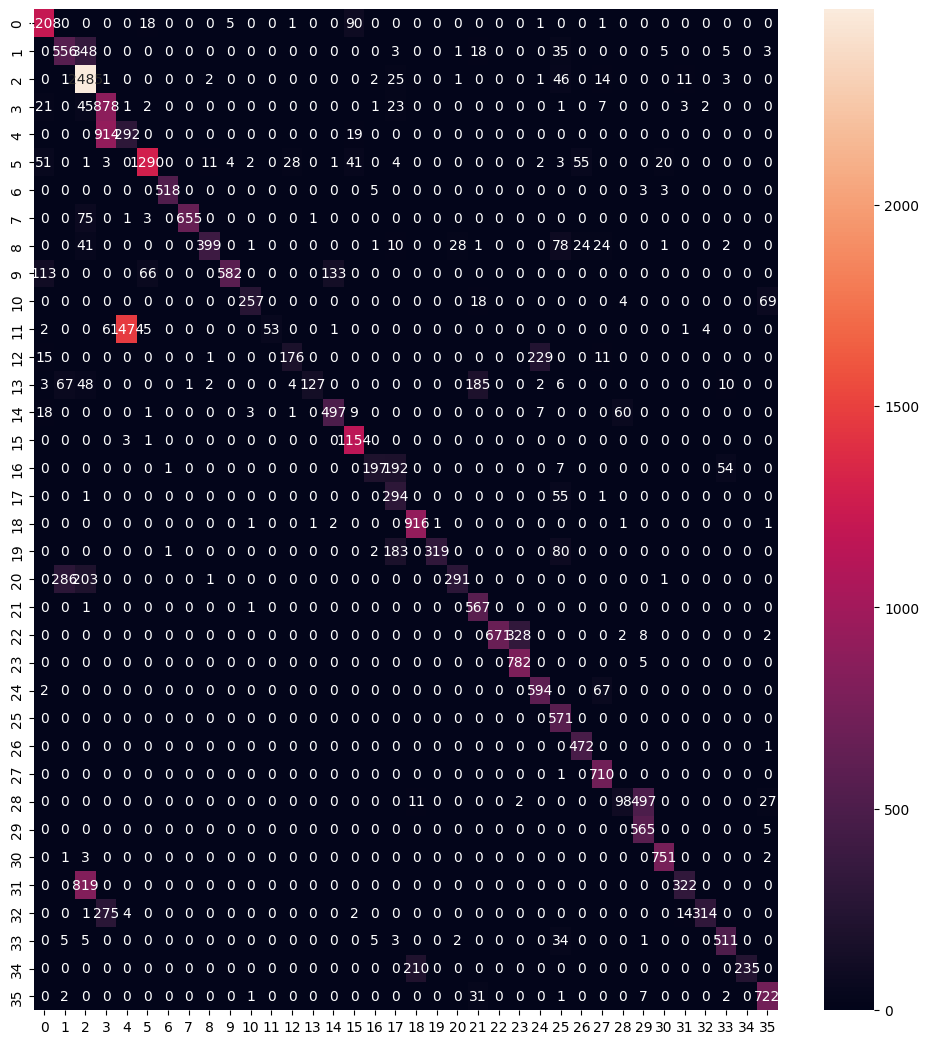

Classification Report
              precision    recall  f1-score   support

           0       0.84      0.91      0.88      1324
           1       0.61      0.57      0.59       974
           2       0.61      0.96      0.75      2592
           3       0.42      0.89      0.57       984
           4       0.16      0.24      0.19      1225
           5       0.93      0.85      0.89      1516
           6       1.00      0.98      0.99       529
           7       1.00      0.89      0.94       735
           8       0.96      0.65      0.78       610
           9       0.98      0.65      0.78       894
          10       0.97      0.74      0.84       348
          11       1.00      0.03      0.07      1546
          12       0.84      0.41      0.55       432
          13       0.98      0.28      0.43       455
          14       0.78      0.83      0.81       596
          15       0.88      1.00      0.93      1158
          16       0.92      0.44      0.59       451
     

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    labels = sorted(list(set(y_true)))
    cmx_data = confusion_matrix(y_true, y_pred, labels=labels)
    
    df_cmx = pd.DataFrame(cmx_data, index=labels, columns=labels)
 
    fig, ax = plt.subplots(figsize=(12, 13))
    sns.heatmap(df_cmx, annot=True, fmt='g' ,square=False)
    ax.set_ylim(len(set(y_true)), 0)
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

# Tensorflow-Lite用のモデルへ変換

In [16]:
# 推論専用のモデルとして保存
model.save(model_save_path, include_optimizer=False)

C:\Users\lachu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [17]:
# モデルを変換(量子化)
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: C:\Users\lachu\AppData\Local\Temp\tmpe7pz5ufj\assets


INFO:tensorflow:Assets written to: C:\Users\lachu\AppData\Local\Temp\tmpe7pz5ufj\assets


7996

# 推論テスト

In [18]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

In [19]:
# 入出力テンソルを取得
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [20]:
interpreter.set_tensor(input_details[0]['index'], np.array([X_test[0]]))

In [21]:
%%time
# 推論実施
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])

CPU times: total: 0 ns
Wall time: 0 ns


In [22]:
print(np.squeeze(tflite_results))
print(np.argmax(np.squeeze(tflite_results)))

[9.4108864e-06 2.7070665e-01 3.1566885e-01 1.4448481e-02 1.3726304e-02
 3.5999429e-03 2.3066619e-04 9.2559941e-03 4.1585129e-02 5.8742394e-06
 6.5249784e-05 5.6804479e-03 2.4429045e-04 1.0498233e-02 1.3052397e-03
 9.1228962e-05 9.8178703e-03 2.0803185e-02 1.1396658e-03 6.2056672e-05
 7.0160836e-02 1.9770693e-02 9.5284783e-04 6.4609741e-04 3.9223512e-05
 2.6288917e-02 1.6186539e-03 6.8408982e-03 2.0162933e-04 3.8213623e-03
 2.4675198e-02 7.3246829e-02 1.3026925e-02 2.1287585e-02 4.2006664e-05
 1.8435564e-02 6.1370574e-12]
2
